In [1]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import seaborn as sns
from bayesian_dem_model import (
    LOGT, TRESP_DLOGT, FACTOR, N_MC_PREDICTIONS, k_matrix, kernel,
    build_model, img_scale, em_scale, run_mc_inference
)

In [2]:
root2pi = (2. * np.pi)**0.5
nt = 18   # Number of temperature bins
nf = 6    # Number of AIA EUV channels

def create_dem(d1, mu, s):
    """
    Generate a Gaussian DEM and simulate the corresponding noisy AIA images.

    Models the DEM as a Gaussian in log-temperature space, forward-models it
    through the AIA temperature response to produce synthetic DN/s intensities,
    and adds photon shot noise to simulate observed images.

    Parameters
    ----------
    d1 : float
        Total emission measure [cm^-5]. Controls the amplitude of the Gaussian DEM.
    mu : float
        Peak temperature of the DEM in log10(T/K)
    s : float
        Width (standard deviation) of the Gaussian DEM in log10(T/K).

    Returns
    -------
    dem_mod : np.ndarray, shape (18,)
        Gaussian DEM values [cm^-5 K^-1] evaluated at each temperature bin.
    img_sim : np.ndarray, shape (512, 512, 6)
        Simulated AIA images in DN/s with realistic noise for each EUV channel.
    """

    # Gaussian DEM
    dem_mod = (d1 / (root2pi * s)) * np.exp(-(LOGT - mu)**2 / (2 * s**2))

    # Forward model: convolve DEM with AIA temperature response to get DN/s per channel
    init_mat = np.zeros([nt, nf])
    for i in range(0, nf):
        init_mat[:, i] = dem_mod * np.transpose(k_matrix)[:, i] * FACTOR
    pixel = np.sum(init_mat, axis=0)


    # Effective gain [electrons/DN] for each AIA channel (94, 131, 171, 193, 211, 335 Å)
    gains = np.array([18.3, 17.6, 17.7, 18.3, 18.3, 17.6])

    # DN-to-photon conversion factor
    conv = gains * np.array([94, 131, 171, 193, 211, 335]) / 3397.

    # Read noise [DN] per pixel for each channel
    read_noise = np.array([1.14, 1.18, 1.15, 1.20, 1.20, 1.18])

    # Assume 2.9 s effective exposure time)
    pixel_exp = pixel * 2.9

    # Shotnoise
    shotnoise = ((conv * pixel_exp)**0.5) / conv / 2.9

    nse = (read_noise**2 + shotnoise**2)**0.5

    # Gaussian noise
    noise = np.random.randn(512, 512, 6) * nse[np.newaxis, np.newaxis]

    # Simulated image: noiseless DN/s + noise realisation
    img_sim = noise + pixel[np.newaxis, np.newaxis]

    return dem_mod, img_sim

In [3]:
d1=6e20
mu_1=6.2
s_1=0.2

dem_mod,img_sim = create_dem(d1,mu_1,s_1)
_,test_model = build_model()
test_model.load_weights('dropout_weights.h5')

dem_list,img_list = run_mc_inference(
    test_model,
    img_sim,
    n_samples=N_MC_PREDICTIONS,
    device="/device:CPU:0")

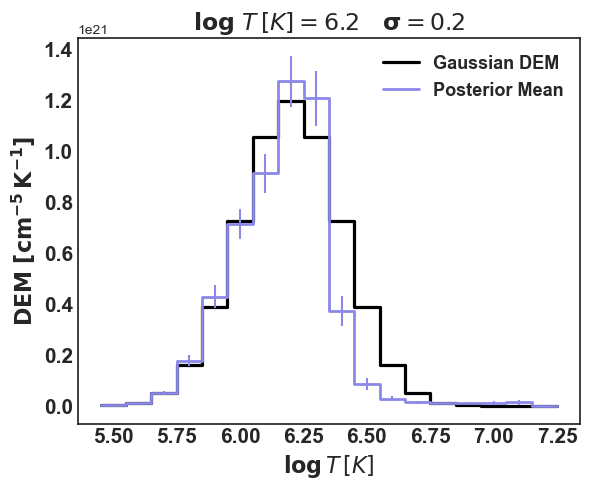

In [4]:
# Temperature bin edges for step plot (one extra edge on each side)
logt_step = np.linspace(5.45, 7.25, 19)

# ── Posterior mean and uncertainty ────────────────────────────────────────────
# Average predicted DEM over all spatial pixels for each forward pass
dem_val = [i[0].mean(axis=(0, 1)) for i in dem_list]
dem_sim_mean = np.mean(dem_val, axis=0)

# Pixel-wise std across forward passes (epistemic uncertainty)
dem_std = [np.reshape(i[0] / 1e19, (512 * 512, 18)) for i in dem_list]
dem_sim_err  = 1e19 * np.mean(np.std(dem_std, axis=0), axis=0)

# ── Figure setup ──────────────────────────────────────────────────────────────
plt.style.use('seaborn-v0_8-white')
fig, ax = plt.subplots(figsize=(6, 5))

# ── Reference Gaussian DEM ────────────────────────────────────────────────────
ax.step(
    logt_step,
    np.insert(dem_mod, 0, dem_mod[0]),
    linestyle='-',
    linewidth=2.3,
    color='#000000',
    label='Gaussian DEM',
)

# ── Posterior mean DEM ────────────────────────────────────────────────────────
ax.step(
    logt_step,
    np.insert(dem_sim_mean, 0, dem_sim_mean[0]),
    color='#8a89e9',
    linewidth=2,
    label='Posterior Mean',
)

# Uncertainty error bars at bin centres
ax.errorbar(
    LOGT,
    dem_sim_mean,
    yerr=dem_sim_err,
    fmt='none',
    ecolor='#8a89e9',
    elinewidth=1.5,
)

# ── Formatting ────────────────────────────────────────────────────────────────
ax.set_title(
    rf'$\mathbf{{log}}\ T\,[K] = {mu_1}\quad \mathbf{{\sigma}}={s_1}$',
    fontsize=17,
    fontweight='bold',
)
ax.set_xlabel(r'$\mathbf{log}\,T\,[K]$', fontsize=16, fontweight='bold')
ax.set_ylabel(r'$\mathbf{DEM\ [cm^{-5}\,K^{-1}]}$', fontsize=16, fontweight='bold')
ax.tick_params(axis='both', which='major', labelsize=15, direction='in')

for label in ax.get_xticklabels() + ax.get_yticklabels():
    label.set_fontweight('bold')

legend = ax.legend(fontsize=13)
for text in legend.get_texts():
    text.set_fontweight('bold')

plt.tight_layout()
plt.show()